# Exploratory Data Analysis

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

df = pd.read_csv('../data/processed/sleep_data.csv', parse_dates=['night', 'bedtime', 'wake_time'])

In [2]:
sns.set_theme(palette='Dark2')

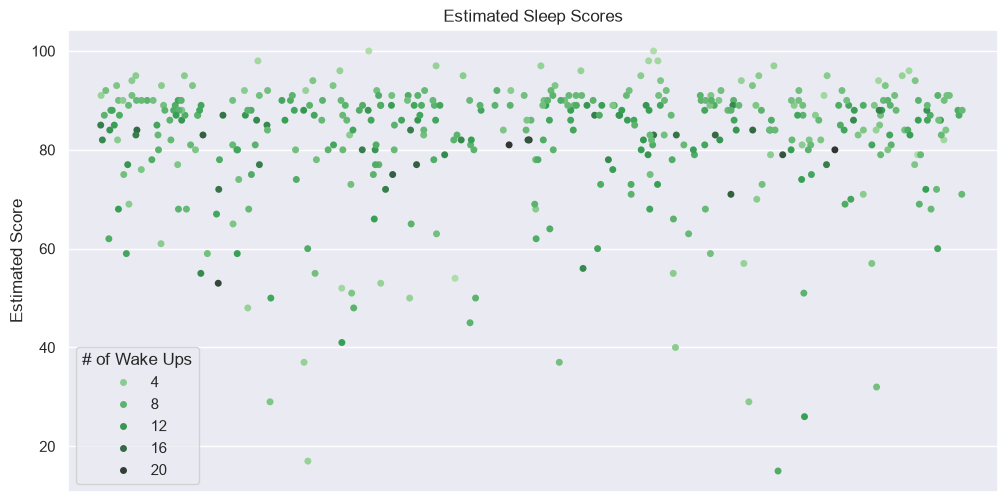

In [3]:
np.random.seed(42)

plt.figure(figsize=(12,6))

sns.stripplot(data=df, y='est_score', hue='wake_ups', jitter=0.47, palette='Greens_d')

plt.title('Estimated Sleep Scores')
plt.ylabel('Estimated Score')
plt.legend(title='# of Wake Ups')

plt.savefig('../visualizations/estimated-sleep-scores.png', bbox_inches='tight')
plt.show()

## Is there a relation between seasons and good sleep?

### Sleep scores by month

In [4]:
sleep_scores_by_month = df.groupby(df['night'].dt.to_period('M')).agg(
    score=('est_score', 'mean'),
    count=('est_score', 'count')
)

sleep_scores_by_month

,score,count
night,,
2025-09,86.083333,12
2025-10,80.296296,27
2025-11,82.928571,28
2025-12,78.193548,31
2026-01,80.300000,30
2026-02,81.821429,28
2026-03,82.275862,29
2026-04,77.433333,30
2026-05,82.870968,31


Even though 2025-09 shows the highest average sleep score, it should be taken with a grain of salt. It is the only month that has less than 20 entries (12 to be exact), and the data could be positively skewed because of it.

In [5]:
sleep_statistics_by_month = sleep_scores_by_month['score'].describe()

mean_sleep_score = sleep_statistics_by_month['mean']

sleep_statistics_by_month

count    15.000000
mean     81.759025
std       2.646353
min      76.933333
25%      80.298148
50%      82.703704
75%      83.084975
max      86.083333
Name: score, dtype: float64

The statistics table helps us better understand the average score per month table above.

- The lowest score is in June 2026, even though temperates are not yet extremely high.
- If we exclude September 2025 (too few entries), the highest average sleep score is in July 2026.
- Winter is more often below the mean sleep score, compared to summer.

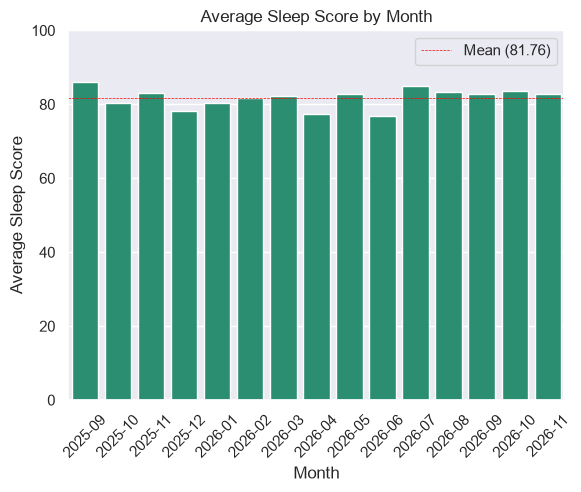

In [6]:
sns.barplot(x=sleep_scores_by_month.index, y=sleep_scores_by_month['score'])

plt.axhline(
    mean_sleep_score,
    color='red',
    linestyle='--',
    linewidth=0.5,
    label=f'Mean ({mean_sleep_score:.2f})'
)

plt.ylim(0, 100)
plt.xticks(rotation=45)

plt.title('Average Sleep Score by Month')
plt.xlabel('Month')
plt.ylabel('Average Sleep Score')
plt.legend()

plt.savefig('../visualizations/average-sleep-score-by-month.png', bbox_inches='tight')
plt.show()

It seems liks summer and autumn have the overall highest sleep scores, with winter and spring being slightly worse. There also seems to be a slight upward general trend, although it's hard to tell with just one year of data.

### Average wake ups by month

In [7]:
average_wake_ups_per_month = df.groupby(df['night'].dt.to_period('M')).agg(
    wake_ups=('wake_ups', 'mean'),
    count=('wake_ups', 'count')
)

average_wake_ups_per_month

,wake_ups,count
night,,
2025-09,9.916667,12
2025-10,10.259259,27
2025-11,7.071429,28
2025-12,9.451613,31
2026-01,6.900000,30
2026-02,7.678571,28
2026-03,7.448276,29
2026-04,8.733333,30
2026-05,8.096774,31


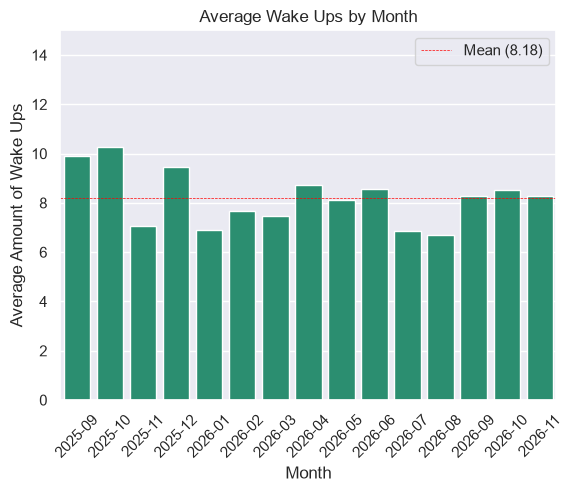

In [8]:
sns.barplot(x=average_wake_ups_per_month.index, y=average_wake_ups_per_month['wake_ups'])

plt.axhline(
    average_wake_ups_per_month['wake_ups'].mean(),
    color='red',
    linestyle='--',
    linewidth=0.5,
    label=f'Mean ({average_wake_ups_per_month['wake_ups'].mean():.2f})'
)

plt.ylim(0, 15)
plt.xticks(rotation=45)

plt.title('Average Wake Ups by Month')
plt.xlabel('Month')
plt.ylabel('Average Amount of Wake Ups')
plt.legend()

plt.savefig('../visualizations/average-wake-ups-by-month.png', bbox_inches='tight')
plt.show()

The average amount of wake ups per month seems to be telling a similar story as the average sleep score, but with more variability. July and August 2026 are the months with least amount of wake ups, but also November 2025 and January 2026 have similar average amounts.

With the amount of wake ups there doesn't seem to be any general trend.